# Hm0 prediction with a U-Net (2005)

U-Net counterpart of `iEMs_Code.ipynb` (Random Forest).

The text files hold one row per grid cell per hour (8760 hours × 29 lat × 45 lon,
0.25°, land cells have `Hm0 = NaN`). The RF treated every row independently; here
the rows are reshaped into **maps**, and the U-Net predicts the whole Hm0 field of an
hour from the wind/pressure fields, so it can use spatial context (fetch, coastline,
upwind conditions).

Differences from the RF notebook, by design:

| | RF notebook | this notebook |
|---|---|---|
| sample | one grid cell | one hourly map (29×45) |
| inputs | Lat, Lon, u10, v10, MSLP | u10, v10, wind speed, MSLP at lags `LAGS` + Lat, Lon, ocean mask |
| split | random rows (leaks between neighbouring hours/cells) | chronological: Jan–Aug train, Sep validation, Oct–Dec test |
| uncertainty band | spread of the 300 trees | spread of MC-dropout passes |
| feature importance | impurity importance | permutation importance (RMSE increase) |
| maps | all rows, incl. training rows | test period only |

Outputs (in `OUTDIR`): `metrics.csv`, `feature_importance.csv/.png`, `obs_vs_pred_ci.png`,
`actual_vs_predicted_test_sample.txt`, `map_*.png`, plus `training_curve.png`,
`example_snapshot.png` and the trained weights `unet_best.pt`.

Requires: `numpy pandas scikit-learn matplotlib torch`.

In [1]:
from __future__ import annotations

import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# -----------------------------
# USER SETTINGS
# -----------------------------
# Data: read X_2005.txt / Y_2005.txt from DATA_DIR if present, otherwise straight from the zip.
DATA_DIR = Path("../../Copy of Dataset and code - Wave Power")
ZIP_PATH = Path("../../Copy of Dataset and code - Wave Power.zip")
X_NAME, Y_NAME = "X_2005.txt", "Y_2005.txt"

OUTDIR = Path("unet_2005_outputs")
OUTDIR.mkdir(exist_ok=True, parents=True)
GRID_CACHE = OUTDIR / "grids_2005.npz"   # parsed (time, lat, lon) arrays; delete to re-parse

RANDOM_SEED = 42

# Chronological split, as [start, end) hour indices (2005 is hourly: 8760 steps)
TRAIN_HOURS = (0, 243 * 24)          # 1 Jan – 31 Aug
VAL_HOURS   = (243 * 24, 273 * 24)   # September (early stopping / LR schedule)
TEST_HOURS  = (273 * 24, 365 * 24)   # 1 Oct – 31 Dec

# Wind/pressure history fed to the network: fields at t - lag for each lag (hours).
# Waves respond to wind over the previous hours, and swell arrives from upwind.
LAGS = [0, 1, 3, 6, 12, 24]

# U-Net
BASE_CHANNELS = 32
DEPTH = 3            # number of 2x downsamplings; the grid is zero-padded to a multiple of 2**DEPTH
DROPOUT = 0.1        # also used for the MC-dropout uncertainty band

# Training
BATCH_SIZE = 32
EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 8         # early stopping on validation RMSE

# Plot settings
MC_SAMPLES = 20
PLOT_SUBSAMPLE = 60_000
CI_BINS = 80
ADD_PM10_ENVELOPE = True

PAIRS_OUT = OUTDIR / "actual_vs_predicted_test_sample.txt"
PAIRS_SEP = "\t"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Device:", DEVICE)

Device: cuda


In [3]:
# -----------------------------
# LOAD ROWS -> (time, lat, lon) GRIDS
# -----------------------------
def open_source(name: str):
    p = DATA_DIR / name
    if p.exists():
        return open(p, "rb")
    return zipfile.ZipFile(ZIP_PATH).open(name)


def load_grids() -> dict:
    if GRID_CACHE.exists():
        with np.load(GRID_CACHE) as d:
            return {k: d[k] for k in d.files}

    print("Parsing text files (one-off, cached afterwards)...")
    with open_source(X_NAME) as f:
        X = pd.read_csv(f, header=None, usecols=range(5), dtype=np.float32).to_numpy()
    with open_source(Y_NAME) as f:
        y = pd.read_csv(f, header=None, usecols=[0], dtype=np.float32).to_numpy()[:, 0]
    if len(X) != len(y):
        raise ValueError(f"X has {len(X)} rows but Y has {len(y)}")

    lat_vals = np.unique(X[:, 0])
    lon_vals = np.unique(X[:, 1])
    nlat, nlon = len(lat_vals), len(lon_vals)
    ncell = nlat * nlon
    if len(X) % ncell:
        raise ValueError(f"{len(X)} rows is not a whole number of {nlat}x{nlon} grids")
    nt = len(X) // ncell

    # rows come as consecutive blocks of one full grid per hour
    t = np.arange(len(X)) // ncell
    ilat = np.searchsorted(lat_vals, X[:, 0])
    ilon = np.searchsorted(lon_vals, X[:, 1])
    counts = np.bincount((t * nlat + ilat) * nlon + ilon, minlength=nt * ncell)
    if not (counts == 1).all():
        raise ValueError("Rows are not one-per-cell-per-hour blocks; cannot reshape to grids.")

    fields = np.full((nt, 3, nlat, nlon), np.nan, dtype=np.float32)   # u10, v10, MSLP
    fields[t, :, ilat, ilon] = X[:, 2:5]
    hm0 = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
    hm0[t, ilat, ilon] = y

    grids = dict(fields=fields, hm0=hm0, lat=lat_vals, lon=lon_vals)
    np.savez(GRID_CACHE, **grids)
    return grids


grids = load_grids()
NT, NLAT, NLON = grids["hm0"].shape
OCEAN = np.isfinite(grids["hm0"]).all(axis=0)   # cells with Hm0 at every hour
LAT, LON = grids["lat"], grids["lon"]
print(f"{NT} hours x {NLAT} lat x {NLON} lon; ocean cells: {OCEAN.sum()} / {OCEAN.size}")
print(f"Lat {LAT.min()}..{LAT.max()}, Lon {LON.min()}..{LON.max()}")
assert TEST_HOURS[1] <= NT, "TEST_HOURS goes past the end of the data"

Parsing text files (one-off, cached afterwards)...


8760 hours x 29 lat x 45 lon; ocean cells: 967 / 1305
Lat 50.0..57.0, Lon -15.0..-4.0


In [4]:
# -----------------------------
# INPUT CHANNELS (normalised, padded)
# -----------------------------
VARS = ["u10", "v10", "wind_speed", "MSLP"]
STATIC_NAMES = ["Lat", "Lon", "ocean_mask"]

u, v, p = (grids["fields"][:, i] for i in range(3))
dyn = np.stack([u, v, np.hypot(u, v), p], axis=1)          # (T, 4, H, W)

# normalise with training-period statistics only
train_slice = slice(*TRAIN_HOURS)
mu = np.nanmean(dyn[train_slice], axis=(0, 2, 3)).reshape(1, -1, 1, 1)
sd = np.nanstd(dyn[train_slice], axis=(0, 2, 3)).reshape(1, -1, 1, 1)
dyn = np.nan_to_num((dyn - mu) / sd).astype(np.float32)

lat2d, lon2d = np.meshgrid(LAT, LON, indexing="ij")
scale = lambda a: (2 * (a - a.min()) / (a.max() - a.min()) - 1).astype(np.float32)
static = np.stack([scale(lat2d), scale(lon2d), OCEAN.astype(np.float32)])   # (3, H, W)

# pad H, W up to a multiple of 2**DEPTH (padding is masked out of the loss)
mult = 2 ** DEPTH
PH, PW = -NLAT % mult, -NLON % mult
DYN = np.pad(dyn, ((0, 0), (0, 0), (0, PH), (0, PW)))
STATIC = np.pad(static, ((0, 0), (0, PH), (0, PW)))
TARGET = np.pad(grids["hm0"], ((0, 0), (0, PH), (0, PW)), constant_values=np.nan)
TARGET[:, ~np.pad(OCEAN, ((0, PH), (0, PW)))] = np.nan

LAG_ARR = np.asarray(LAGS)
CHANNEL_NAMES = [f"{var}_lag{L}h" for L in LAGS for var in VARS] + STATIC_NAMES
N_IN = len(CHANNEL_NAMES)

first_valid = max(LAGS)   # need full history
train_times = np.arange(max(TRAIN_HOURS[0], first_valid), TRAIN_HOURS[1])
val_times = np.arange(max(VAL_HOURS[0], first_valid), VAL_HOURS[1])
test_times = np.arange(max(TEST_HOURS[0], first_valid), TEST_HOURS[1])
print(f"Input channels: {N_IN}, padded grid: {DYN.shape[-2]}x{DYN.shape[-1]}")
print(f"Train/val/test maps: {len(train_times)} / {len(val_times)} / {len(test_times)}")


def make_batch(times, shuffled_vars: dict | None = None):
    # Stack lagged fields + static channels for the given hours.
    # shuffled_vars maps a variable index (into VARS) to replacement hours, used for
    # permutation importance (that variable is taken from other hours, at all lags).
    times = np.asarray(times)
    x = DYN[times[:, None] - LAG_ARR[None, :]].copy()        # (B, nlag, 4, H, W)
    for vi, other in (shuffled_vars or {}).items():
        x[:, :, vi] = DYN[np.asarray(other)[:, None] - LAG_ARR[None, :], vi]
    x = x.reshape(len(times), -1, *x.shape[-2:])
    s = np.broadcast_to(STATIC, (len(times),) + STATIC.shape)
    x = np.concatenate([x, s], axis=1)
    return torch.from_numpy(x).to(DEVICE), torch.from_numpy(TARGET[times]).to(DEVICE)

Input channels: 27, padded grid: 32x48
Train/val/test maps: 5808 / 720 / 2208


In [5]:
# -----------------------------
# U-NET
# -----------------------------
def conv_block(cin: int, cout: int, dropout: float) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.Dropout2d(dropout),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, in_ch: int, base: int = 32, depth: int = 3, dropout: float = 0.1):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.down = nn.ModuleList()
        prev = in_ch
        for c in chs[:-1]:
            self.down.append(conv_block(prev, c, dropout))
            prev = c
        self.bottleneck = conv_block(prev, chs[-1], dropout)
        self.up = nn.ModuleList(
            nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))
        )
        self.dec = nn.ModuleList(conv_block(2 * chs[i], chs[i], dropout) for i in reversed(range(depth)))
        self.head = nn.Conv2d(chs[0], 1, 1)

    def forward(self, x):
        skips = []
        for block in self.down:
            x = block(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), skip], dim=1))
        return self.head(x).squeeze(1)   # (B, H, W) Hm0 in metres


def masked_mse(pred, target):
    m = torch.isfinite(target)
    return F.mse_loss(pred[m], target[m])


model = UNet(N_IN, BASE_CHANNELS, DEPTH, DROPOUT).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,933,921


In [6]:
# -----------------------------
# PREDICTION HELPERS
# -----------------------------
@torch.no_grad()
def predict(model, times, mc_dropout: bool = False, shuffled_vars: dict | None = None) -> np.ndarray:
    # Hm0 maps (len(times), NLAT, NLON); land cells are NaN.
    model.eval()
    if mc_dropout:   # dropout on, batch-norm still in eval mode
        for mod in model.modules():
            if isinstance(mod, nn.Dropout2d):
                mod.train()
    out = []
    for i in range(0, len(times), 2 * BATCH_SIZE):
        sl = slice(i, i + 2 * BATCH_SIZE)
        sv = {k: np.asarray(o)[sl] for k, o in (shuffled_vars or {}).items()}
        xb, _ = make_batch(times[sl], sv)
        out.append(model(xb).float().cpu().numpy())
    pred = np.concatenate(out)[:, :NLAT, :NLON].clip(min=0)
    pred[:, ~OCEAN] = np.nan
    return pred


def obs_maps(times) -> np.ndarray:
    o = grids["hm0"][times].copy()
    o[:, ~OCEAN] = np.nan
    return o


def rmse_of(obs, pred) -> float:
    m = np.isfinite(obs) & np.isfinite(pred)
    return float(np.sqrt(np.mean((obs[m] - pred[m]) ** 2)))

epoch   1  train RMSE 1.012  val RMSE 0.466  lr 1.0e-03  (4s)


epoch   2  train RMSE 0.645  val RMSE 0.647  lr 1.0e-03  (3s)


epoch   3  train RMSE 0.601  val RMSE 0.769  lr 1.0e-03  (3s)


epoch   4  train RMSE 0.577  val RMSE 0.599  lr 1.0e-03  (3s)


epoch   5  train RMSE 0.493  val RMSE 0.475  lr 5.0e-04  (3s)


epoch   6  train RMSE 0.450  val RMSE 0.533  lr 5.0e-04  (3s)


epoch   7  train RMSE 0.437  val RMSE 0.579  lr 5.0e-04  (3s)


epoch   8  train RMSE 0.408  val RMSE 0.498  lr 5.0e-04  (3s)


epoch   9  train RMSE 0.391  val RMSE 0.534  lr 2.5e-04  (3s)
Early stopping.


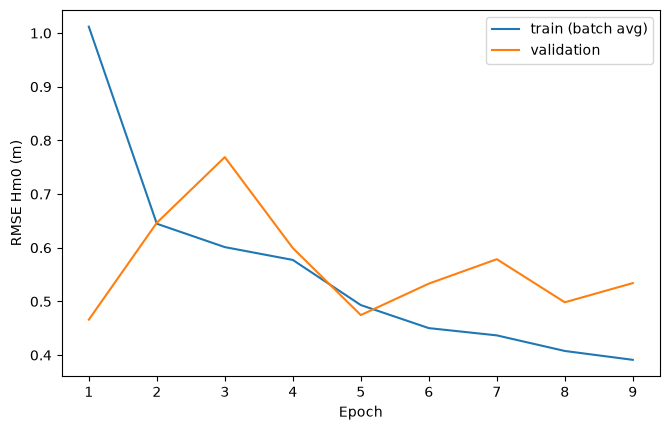

In [7]:
# -----------------------------
# TRAIN (early stopping on validation RMSE)
# -----------------------------
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
rng = np.random.default_rng(RANDOM_SEED)
val_obs = obs_maps(val_times)

history, best, bad = [], np.inf, 0
best_path = OUTDIR / "unet_best.pt"
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    order = rng.permutation(train_times)
    losses = []
    for i in range(0, len(order), BATCH_SIZE):
        xb, yb = make_batch(order[i:i + BATCH_SIZE])
        loss = masked_mse(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())

    train_rmse = float(np.sqrt(np.mean(losses)))
    val_rmse = rmse_of(val_obs, predict(model, val_times))
    sched.step(val_rmse)
    history.append(dict(epoch=epoch, train_rmse=train_rmse, val_rmse=val_rmse,
                        lr=opt.param_groups[0]["lr"]))
    print(f"epoch {epoch:3d}  train RMSE {train_rmse:.3f}  val RMSE {val_rmse:.3f}  "
          f"lr {opt.param_groups[0]['lr']:.1e}  ({time.time() - t0:.0f}s)")

    if val_rmse < best:
        best, bad = val_rmse, 0
        torch.save(model.state_dict(), best_path)
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(torch.load(best_path, map_location=DEVICE))
hist = pd.DataFrame(history)
hist.to_csv(OUTDIR / "training_history.csv", index=False)

plt.figure(figsize=(6.8, 4.4))
plt.plot(hist.epoch, hist.train_rmse, label="train (batch avg)")
plt.plot(hist.epoch, hist.val_rmse, label="validation")
plt.xlabel("Epoch")
plt.ylabel("RMSE Hm0 (m)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTDIR / "training_curve.png", dpi=300)
plt.show()

In [8]:
# -----------------------------
# EVALUATE ON TEST PERIOD
# -----------------------------
pred_te = predict(model, test_times)
obs_te = obs_maps(test_times)
m = np.isfinite(obs_te) & np.isfinite(pred_te)
yte, pte = obs_te[m], pred_te[m]

metrics = pd.DataFrame([{
    "MAE": mean_absolute_error(yte, pte),
    "RMSE": mean_squared_error(yte, pte) ** 0.5,
    "R2": r2_score(yte, pte),
    "val_RMSE": best,
    "n_train_maps": len(train_times),
    "n_test_maps": len(test_times),
    "n_test_pixels": int(m.sum()),
}])
metrics.to_csv(OUTDIR / "metrics.csv", index=False)
print("=== Analytics (test period, ocean cells) ===")
print(metrics.to_string(index=False))

# actual vs predicted for every test pixel, with its hour and location
tt, ii, jj = np.nonzero(m)
pairs = pd.DataFrame({
    "hour_of_year": test_times[tt],
    "Lat": LAT[ii],
    "Lon": LON[jj],
    "actual": yte,
    "predicted": pte,
})
pairs.to_csv(PAIRS_OUT, sep=PAIRS_SEP, index=False, float_format="%.4f")
print(f"\nWrote: {PAIRS_OUT.resolve()}")

=== Analytics (test period, ocean cells) ===
     MAE     RMSE       R2  val_RMSE  n_train_maps  n_test_maps  n_test_pixels
0.436827 0.579262 0.857647  0.466001          5808         2208        2135136



Wrote: /home/michele/phd_choise/off shore/src/off_shore/unet_2005_outputs/actual_vs_predicted_test_sample.txt


wind_speed          0.914199
history (lags>0)    0.910664
u10                 0.097849
MSLP                0.031162
v10                 0.024870


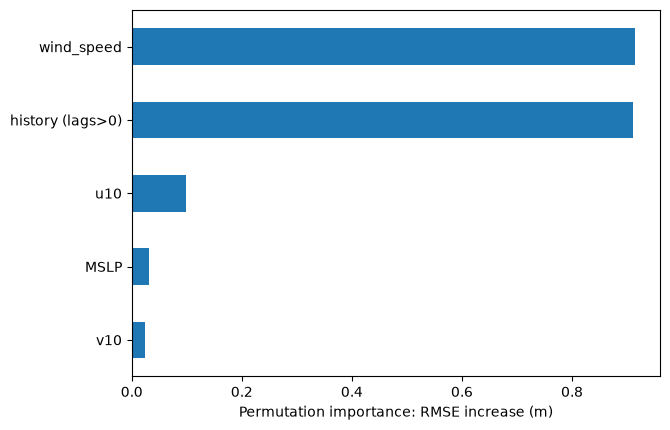

In [9]:
# -----------------------------
# PERMUTATION IMPORTANCE (RMSE increase on test period)
# -----------------------------
# Each variable is replaced, at all lags, by the same variable from a random other test hour.
# "history (lags>0)" shuffles only the lagged fields of all variables, keeping the current hour.
# Lat/Lon/mask are static (identical every hour), so permuting them across time is meaningless;
# they are left out.
perm_rng = np.random.default_rng(RANDOM_SEED)
base_rmse = rmse_of(obs_te, pred_te)
imp = {}
for vi, name in enumerate(VARS):
    shuffled = perm_rng.permutation(test_times)
    imp[name] = rmse_of(obs_te, predict(model, test_times, shuffled_vars={vi: shuffled})) - base_rmse

hist_idx = [li * len(VARS) + vi for li, L in enumerate(LAGS) if L > 0 for vi in range(len(VARS))]
if hist_idx:
    shuffled = perm_rng.permutation(test_times)
    preds = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(test_times), 2 * BATCH_SIZE):
            xb, _ = make_batch(test_times[i:i + 2 * BATCH_SIZE])
            xs, _ = make_batch(shuffled[i:i + 2 * BATCH_SIZE])
            xb[:, hist_idx] = xs[:, hist_idx]
            preds.append(model(xb).float().cpu().numpy())
    p_hist = np.concatenate(preds)[:, :NLAT, :NLON].clip(min=0)
    p_hist[:, ~OCEAN] = np.nan
    imp["history (lags>0)"] = rmse_of(obs_te, p_hist) - base_rmse

fi = pd.Series(imp, name="RMSE_increase_m").sort_values(ascending=False)
fi.to_csv(OUTDIR / "feature_importance.csv")
print(fi.to_string())

plt.figure(figsize=(6.8, 4.4))
fi.iloc[::-1].plot(kind="barh")
plt.xlabel("Permutation importance: RMSE increase (m)")
plt.tight_layout()
plt.savefig(OUTDIR / "feature_importance.png", dpi=300)
plt.show()

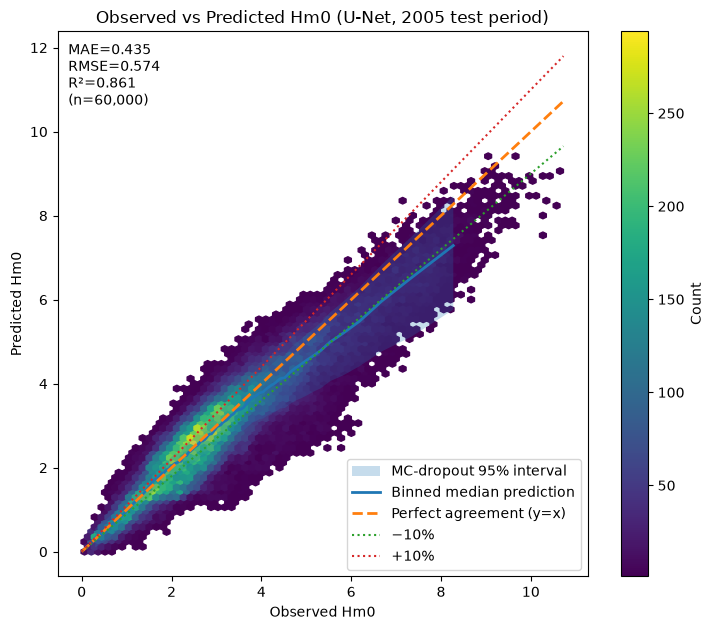

In [10]:
# -----------------------------
# OBS vs PRED PLOT (MC-dropout interval + 1:1 line)
# -----------------------------
def plot_obs_pred_with_ci(
    yt: np.ndarray,
    mc_preds: np.ndarray,      # (MC_SAMPLES, n) predictions for the same pixels
    out_png: Path,
    n_bins: int = 80,
    add_pm10: bool = True,
):
    pred_med = np.median(mc_preds, axis=0)
    pred_lo = np.percentile(mc_preds, 2.5, axis=0)
    pred_hi = np.percentile(mc_preds, 97.5, axis=0)

    # ribbon by observed bins
    order = np.argsort(yt)
    yt_s, med_s, lo_s, hi_s = yt[order], pred_med[order], pred_lo[order], pred_hi[order]
    edges = np.linspace(0, len(yt_s), n_bins + 1).astype(int)
    x_bin, med_b, lo_b, hi_b = (np.empty(n_bins) for _ in range(4))
    for b in range(n_bins):
        a, c = edges[b], max(edges[b + 1], edges[b] + 1)
        x_bin[b] = np.nanmean(yt_s[a:c])
        med_b[b] = np.nanmean(med_s[a:c])
        lo_b[b] = np.nanmean(lo_s[a:c])
        hi_b[b] = np.nanmean(hi_s[a:c])

    err = yt - pred_med
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    r2 = 1 - np.sum(err ** 2) / np.sum((yt - yt.mean()) ** 2)

    fig, ax = plt.subplots(figsize=(7.4, 6.4))
    hb = ax.hexbin(yt, pred_med, gridsize=70, mincnt=1)
    fig.colorbar(hb, ax=ax).set_label("Count")
    ax.fill_between(x_bin, lo_b, hi_b, alpha=0.25, label="MC-dropout 95% interval")
    ax.plot(x_bin, med_b, linewidth=2.0, label="Binned median prediction")

    mn = float(min(yt.min(), pred_med.min()))
    mx = float(max(yt.max(), pred_med.max()))
    ax.plot([mn, mx], [mn, mx], linestyle="--", linewidth=2.0, label="Perfect agreement (y=x)")
    if add_pm10:
        ax.plot([mn, mx], [0.9 * mn, 0.9 * mx], linestyle=":", linewidth=1.5, label="−10%")
        ax.plot([mn, mx], [1.1 * mn, 1.1 * mx], linestyle=":", linewidth=1.5, label="+10%")

    ax.set_xlabel("Observed Hm0")
    ax.set_ylabel("Predicted Hm0")
    ax.set_title("Observed vs Predicted Hm0 (U-Net, 2005 test period)")
    ax.text(0.02, 0.98, f"MAE={mae:.3f}\nRMSE={rmse:.3f}\nR²={r2:.3f}\n(n={len(yt):,})",
            transform=ax.transAxes, va="top")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(out_png, dpi=300)
    plt.show()


# random subset of test pixels, MC_SAMPLES stochastic passes over the test period
flat_idx = np.flatnonzero(m)
pick = np.random.default_rng(RANDOM_SEED).choice(flat_idx, size=min(PLOT_SUBSAMPLE, flat_idx.size), replace=False)
mc = np.stack([predict(model, test_times, mc_dropout=True).ravel()[pick] for _ in range(MC_SAMPLES)])
plot_obs_pred_with_ci(obs_te.ravel()[pick], mc, OUTDIR / "obs_vs_pred_ci.png",
                      n_bins=CI_BINS, add_pm10=ADD_PM10_ENVELOPE)

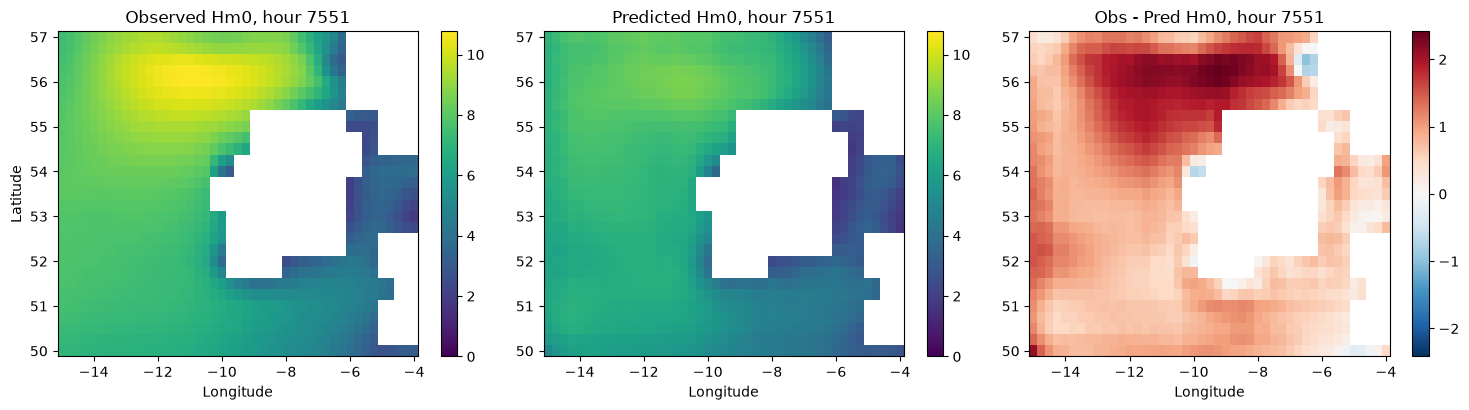

Saved outputs to: /home/michele/phd_choise/off shore/src/off_shore/unet_2005_outputs
 - actual_vs_predicted_test_sample.txt
 - example_snapshot.png
 - feature_importance.csv
 - feature_importance.png
 - grids_2005.npz
 - map_error_mean.png
 - map_observed_hm0.png
 - map_predicted_hm0.png
 - map_rmse.png
 - metrics.csv
 - obs_vs_pred_ci.png
 - training_curve.png
 - training_history.csv
 - unet_best.pt


In [11]:
# -----------------------------
# MAPS (test period)
# -----------------------------
import warnings
warnings.filterwarnings("ignore", message="Mean of empty slice")   # land cells are all-NaN

d_lat = float(np.median(np.diff(LAT)))
d_lon = float(np.median(np.diff(LON)))
EXTENT = (LON.min() - d_lon / 2, LON.max() + d_lon / 2, LAT.min() - d_lat / 2, LAT.max() + d_lat / 2)


def save_map(arr, title, path, cmap="viridis", center=False):
    plt.figure()
    kw = {}
    if center:
        lim = np.nanmax(np.abs(arr))
        kw = dict(vmin=-lim, vmax=lim)
    plt.imshow(arr, origin="lower", extent=EXTENT, aspect="auto", cmap=cmap, **kw)
    plt.colorbar()
    plt.title(title)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.savefig(path, dpi=300)
    plt.close()


err = obs_te - pred_te
save_map(np.nanmean(obs_te, axis=0), "Observed Hm0 (Oct–Dec 2005)", OUTDIR / "map_observed_hm0.png")
save_map(np.nanmean(pred_te, axis=0), "Predicted Hm0 (U-Net, Oct–Dec 2005)", OUTDIR / "map_predicted_hm0.png")
save_map(np.nanmean(err, axis=0), "Mean Error (Obs - Pred) Hm0", OUTDIR / "map_error_mean.png",
         cmap="RdBu_r", center=True)
save_map(np.sqrt(np.nanmean(err ** 2, axis=0)), "RMSE per Grid Cell (Hm0)", OUTDIR / "map_rmse.png",
         cmap="magma")

# one example hour: the stormiest test hour
k = int(np.nanargmax(np.nanmean(obs_te, axis=(1, 2))))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
vmax = np.nanmax([obs_te[k], pred_te[k]])
for ax, arr, title, kw in [
    (axes[0], obs_te[k], "Observed", dict(vmin=0, vmax=vmax)),
    (axes[1], pred_te[k], "Predicted", dict(vmin=0, vmax=vmax)),
    (axes[2], err[k], "Obs - Pred", dict(cmap="RdBu_r", vmin=-np.nanmax(np.abs(err[k])), vmax=np.nanmax(np.abs(err[k])))),
]:
    im = ax.imshow(arr, origin="lower", extent=EXTENT, aspect="auto", **kw)
    fig.colorbar(im, ax=ax)
    ax.set_title(f"{title} Hm0, hour {test_times[k]}")
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.tight_layout()
fig.savefig(OUTDIR / "example_snapshot.png", dpi=200)
plt.show()

print(f"Saved outputs to: {OUTDIR.resolve()}")
for f in sorted(OUTDIR.iterdir()):
    print(" -", f.name)